In [1]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

In [2]:
kk = (1,20)

In [3]:
def example2_logistic(n=2000):
    U = torch.rand(n, 2)
    X = torch.special.logit(U)
    mg = MissingnessGenerator(U)
    M = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.special.logit(torch.rand(n, 2))
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [4]:
n = 2000
U = torch.rand(n, 2)
X = torch.special.logit(U)
mg = MissingnessGenerator(U)
M = mg.example2(U[:,0], U[:, 1])
Xtest = torch.special.logit(torch.rand(n, 2))
gmm = GaussianMixtureMAR(kk)
gmm.fit(X, M)
Xtilde = gmm.sample(n)[0]

In [5]:
# Standard logistic PDF
x = np.linspace(-4, 4, 500)
pdf = np.exp(-x) / (1 + np.exp(-x))**2

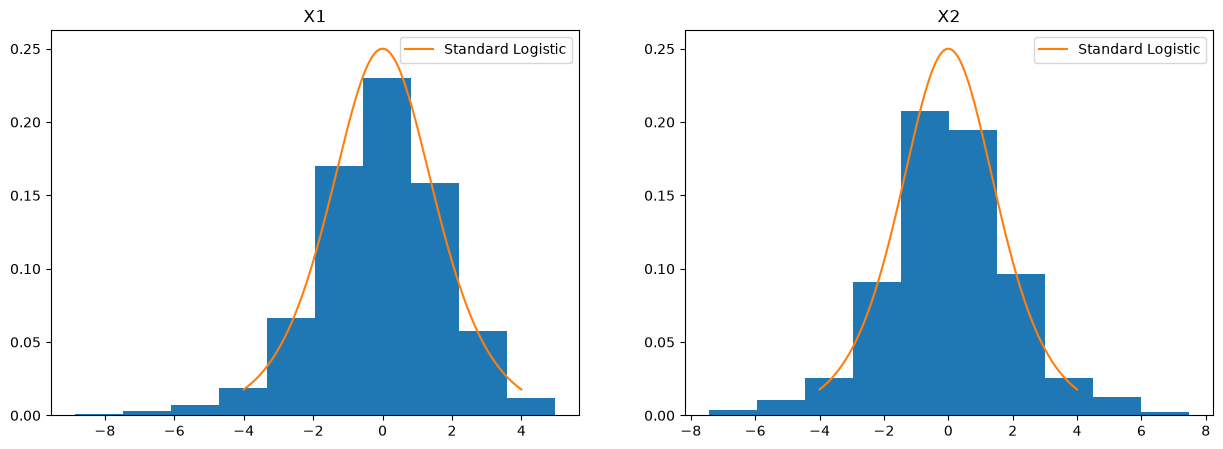

In [11]:
_, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].hist(Xtilde[:,0], density=True)
axes[0].plot(x, pdf, label="Standard Logistic")
axes[0].legend()
axes[0].set_title('X1')

axes[1].hist(Xtilde[:,1], density=True)
axes[1].plot(x, pdf, label="Standard Logistic")
axes[1].legend()
axes[1].set_title('X2')

plt.show()

In [12]:
def example2_normal(n=2000):
    U = torch.rand(n, 2)
    X = torch.distributions.Normal(0, 1).icdf(U)
    mg = MissingnessGenerator(U)
    M = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.randn(n, 2) # N2(0,1)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [58]:
n_runs = 50

In [ ]:
res = [example2_normal() for _ in range(50)]
res = np.array(res)

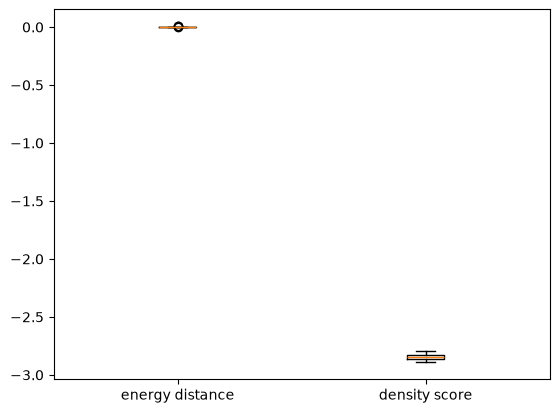

In [61]:
plt.boxplot(res, tick_labels=['energy distance', 'density score'])
plt.show()

In [51]:
n = 2000
U = torch.rand(n, 2)
X = torch.distributions.Normal(0, 1).icdf(U)
mg = MissingnessGenerator(U)
M = mg.example2(U[:,0], U[:, 1])
gmm = GaussianMixtureMAR(kk)
gmm.fit(X, M)

In [52]:
Xtilde = gmm.sample(n)[0]

In [63]:
from scipy.stats import norm
x = np.linspace(-4, 4, 500)

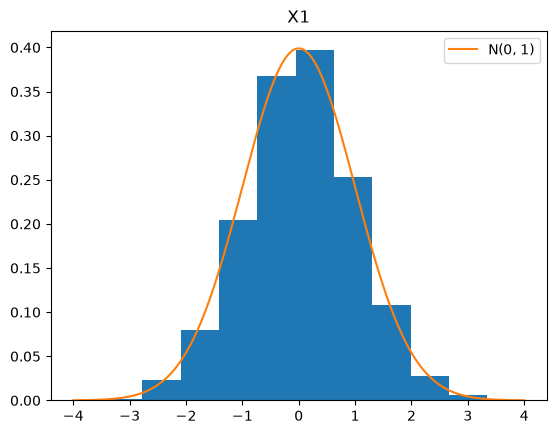

In [66]:
plt.hist(Xtilde[:,0], density=True)
plt.title('X1')
plt.plot(x, norm.pdf(x), label="N(0, 1)")
plt.legend()
plt.show()

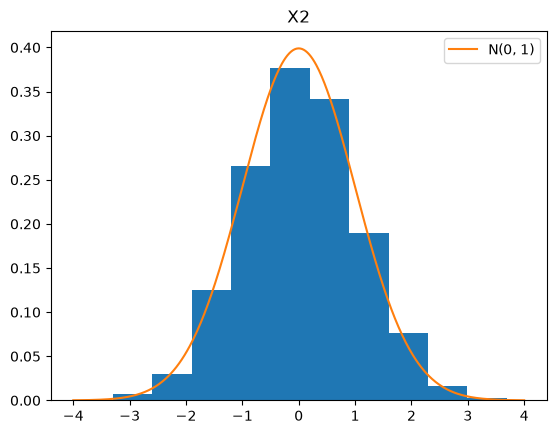

In [67]:
plt.hist(Xtilde[:,1], density=True)
plt.title('X2')
plt.plot(x, norm.pdf(x), label="N(0, 1)")
plt.legend()
plt.show()

In [ ]:
eps_vals = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]

In [ ]:
n = 2000
d = 3
kk = (1, 20)

In [ ]:
k=10
mu0 = torch.rand((k, d)) * 2 - 1 # [-1, 1]
sigma0 = torch.rand((k, d)) * 2 # (0, 2)
pi0 = torch.rand(k) + 0.1
pi0 = pi0 / pi0.sum()

In [ ]:
dg = DataGenerator('gaussian_mixture', mu=mu0, sigma=sigma0, pi=pi0)

In [ ]:
def run_gaussian_mixture(dg, eps):
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, eps)
    Xtest = dg.sample_truth(n, d)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [ ]:
def run_normal(dg, eps):
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, eps)
    Xtest = dg.sample_truth(n, d)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    q1 = np.quantile(Xtilde[:,0], 0.1).item()
    return ed, ds, q1

In [ ]:
def run_old(dg, eps, m=20):
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, eps)
    Xtest = [dg.sample_truth(n, d) for _ in range(m)]
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = [gmm.sample(n)[0] for _ in range(m)]
    ed = [energy_distance(Xtest[i], Xtilde[i]).item() for i in range(m)]
    ds = [gmm.evaluate(Xtest[i]).item() for i in range(m)]
    return ed, ds

In [ ]:
n_runs = 20

In [ ]:
results = Parallel(n_jobs=-1)( 
    delayed(run_gaussian_mixture)(dg, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

In [ ]:
res = np.array(results).reshape(n_runs, len(eps_vals), 2)

In [ ]:
def plot(res, eps):

    color = '#90be6d'

    _, _, m = res.shape
    fig, axes = plt.subplots(1, m, figsize=(14, 4))

    ylabs = ['energy distance', 'density score', 'quantile 0.1']

    for i, ax in enumerate(axes):

        ax.grid(
            True,
            linestyle='--',
            alpha=0.5
        )

        bp = ax.boxplot(
            res[:, :, i],
            patch_artist=True,
            showfliers=False,
            widths=0.3
        )

        ax.set_xticks(
            range(1, len(eps) + 1),
            eps,
            fontsize=11
        )

        ax.set_ylabel(ylabs[i])

        ax.set_xlabel(r'$\epsilon$')

        for patch in bp['boxes']:
            patch.set_facecolor(color)
            patch.set_alpha(0.7)

        # Reference line for subplot 3
        if i == 2:
            ax.axhline(
                #y=-1.282,
                y=-2.197,
                linestyle='--',
                linewidth=1.5
            )

    plt.tight_layout()
    plt.show()

In [ ]:
plot(res, eps_vals)

In [ ]:
dgn = DataGenerator('Normal')
results_n = Parallel(n_jobs=-1)( 
    delayed(run_normal)(dgn, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

In [ ]:
res_n = np.array(results_n).reshape(n_runs, len(eps_vals), 3)
plot(res_n, eps_vals)

In [ ]:
dgl = DataGenerator('Logistic')
results_l = Parallel(n_jobs=-1)( 
    delayed(run_normal)(dgl, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

In [ ]:
res_l = np.array(results_l).reshape(n_runs, len(eps_vals), 3)
plot(res_l, eps_vals)